# Portada

**UNIVERSIDAD AUTONOMA DEL ESTADO DE MEXICO (UAEMex)**

**Investigación de Operaciones**

**Ingeniería en Computación**

**ACTIVDAD: Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook**

**Práctica: 1. Algoritmo de Expansión Mínima (Kruskal)**

**Integrantes del equipo:**
 - David Alberto Ruiz Gonzalez
 - Alexia Guadalupe Sanchez Zamora

**Fecha:**: 18 noviembre de 2026

# Título del problema

**Diseño del cableado de una red de TI con costo mínimo (Árbol de Expansión Mínima – Algoritmo de Kruskal)**

## Descripción y planteamiento

Una empresa de tecnología debe interconectar **9 dispositivos de red** de un edificio: un nodo *Core*, un servidor (*Srv*), cuatro switches (*SW1–SW4*), dos puntos de acceso (*AP1, AP2*) y un laboratorio (*Lab*). Existen 14 posibles tendidos de cable; cada uno tiene un **costo de instalación** (en cientos de USD).

**Objetivo:** conectar todos los dispositivos entre sí (directa o indirectamente) con el **menor costo total de cableado**, sin formar ciclos redundantes.

Esto es exactamente el problema del **árbol de expansión mínima** (*Minimum Spanning Tree*, MST): dado un grafo conexo, ponderado y no dirigido, encontrar el subconjunto de aristas que conecta todos los nodos con peso total mínimo.

### Formulación matemática

Sea $G=(V,E)$ un grafo con $|V|=9$ nodos y $|E|=14$ aristas, donde cada arista $e=(i,j)$ tiene costo $c_e$. Definimos la variable de decisión

$$x_e=\begin{cases}1 & \text{si la arista } e \text{ se instala}\\ 0 & \text{en otro caso}\end{cases}$$

$$\min \; Z=\sum_{e\in E} c_e\,x_e$$

sujeto a:

$$\sum_{e\in E} x_e = |V|-1 = 8,\qquad \sum_{e\in E(S)} x_e \le |S|-1\;\; \forall S\subset V,\qquad x_e\in\{0,1\}$$

(la primera restricción fija el número de aristas de un árbol; la segunda prohíbe ciclos).

### Idea del algoritmo de Kruskal

1. Ordenar todas las aristas de menor a mayor costo.
2. Recorrerlas en ese orden: **aceptar** la arista si une dos componentes distintas, **rechazarla** si formaría un ciclo.
3. Detenerse cuando se tengan $|V|-1$ aristas aceptadas.

Para detectar ciclos usamos la estructura **Union-Find** (conjuntos disjuntos).

## Paso 1. Importación de bibliotecas

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

print("NetworkX:", nx.__version__)
print("Bibliotecas importadas correctamente")

NetworkX: 3.7
Bibliotecas importadas correctamente


## Paso 2. Definición de datos

Cada tupla es `(nodo_origen, nodo_destino, costo)`. Guardamos también las posiciones de los nodos para que todas las gráficas se vean igual.

In [4]:
aristas = [
    ("Core", "Srv", 4), ("Core", "AP2", 8), ("Srv", "SW1", 8), ("Srv", "AP2", 11),
    ("SW1", "SW2", 7), ("SW1", "SW4", 4), ("SW1", "Lab", 2), ("SW2", "SW3", 9),
    ("SW2", "SW4", 14), ("SW3", "SW4", 10), ("SW4", "AP1", 2), ("AP1", "AP2", 1),
    ("AP1", "Lab", 6), ("AP2", "Lab", 7),
]

G = nx.Graph()
G.add_weighted_edges_from(aristas)

pos = {"Core": (0, 1.5), "Srv": (2, 3), "SW1": (5, 3), "SW2": (8, 3),
       "SW3": (10, 1.5), "SW4": (8, 0), "AP1": (5, 0), "AP2": (2, 0),
       "Lab": (5, 1.5)}

df = pd.DataFrame(aristas, columns=["Origen", "Destino", "Costo"])
print("Nodos:", G.number_of_nodes(), "| Aristas:", G.number_of_edges())
print()
print(df.to_string(index=False))

Nodos: 9 | Aristas: 14

Origen Destino  Costo
  Core     Srv      4
  Core     AP2      8
   Srv     SW1      8
   Srv     AP2     11
   SW1     SW2      7
   SW1     SW4      4
   SW1     Lab      2
   SW2     SW3      9
   SW2     SW4     14
   SW3     SW4     10
   SW4     AP1      2
   AP1     AP2      1
   AP1     Lab      6
   AP2     Lab      7


## Paso 3. Gráfica de la red original

Definimos una función `dibujar` que usaremos en todos los pasos: pinta en **verde** las aristas aceptadas, en **rojo punteado** las rechazadas y en **naranja** la arista que se está evaluando.

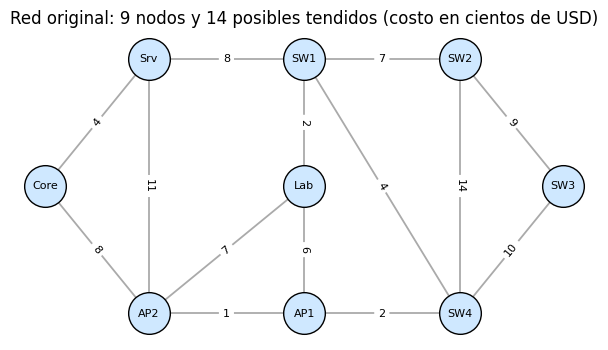

In [5]:
def dibujar(aceptadas=(), rechazadas=(), actual=None, titulo=""):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    acept = {frozenset(e[:2]) for e in aceptadas}
    rech = {frozenset(e[:2]) for e in rechazadas}
    act = frozenset(actual[:2]) if actual else None

    for u, v in G.edges():
        k = frozenset((u, v))
        if k == act:
            kw = dict(edge_color="orange", width=4)
        elif k in acept:
            kw = dict(edge_color="green", width=3.5)
        elif k in rech:
            kw = dict(edge_color="red", width=1.8, style="dashed")
        else:
            kw = dict(edge_color="#aaaaaa", width=1.3)
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax, **kw)

    nx.draw_networkx_nodes(G, pos, node_size=900, node_color="#cfe8ff",
                           edgecolors="black", ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"),
                                 font_size=8, ax=ax)
    ax.set_title(titulo)
    ax.axis("off")
    plt.show()


dibujar(titulo="Red original: 9 nodos y 14 posibles tendidos (costo en cientos de USD)")

## Paso 4. Ordenar las aristas por costo (Kruskal, paso 1)

Kruskal es un algoritmo **voraz**: siempre intenta primero la arista más barata disponible.

In [6]:
ordenadas = sorted(aristas, key=lambda e: e[2])
tabla = pd.DataFrame(ordenadas, columns=["Origen", "Destino", "Costo"])
tabla.index = tabla.index + 1
tabla.index.name = "Orden"
print(tabla.to_string())

      Origen Destino  Costo
Orden                      
1        AP1     AP2      1
2        SW1     Lab      2
3        SW4     AP1      2
4       Core     Srv      4
5        SW1     SW4      4
6        AP1     Lab      6
7        SW1     SW2      7
8        AP2     Lab      7
9       Core     AP2      8
10       Srv     SW1      8
11       SW2     SW3      9
12       SW3     SW4     10
13       Srv     AP2     11
14       SW2     SW4     14


## Paso 5. Estructura Union-Find

Cada nodo comienza como su propia componente. `buscar(x)` devuelve el representante de la componente de `x`; `unir(a, b)` fusiona dos componentes y devuelve `False` si ya eran la misma (es decir, si la arista crearía un **ciclo**).

In [7]:
class UnionFind:
    def __init__(self, nodos):
        self.padre = {n: n for n in nodos}

    def buscar(self, x):
        while self.padre[x] != x:
            self.padre[x] = self.padre[self.padre[x]]   # compresión de caminos
            x = self.padre[x]
        return x

    def unir(self, a, b):
        ra, rb = self.buscar(a), self.buscar(b)
        if ra == rb:
            return False
        self.padre[rb] = ra
        return True

    def componentes(self):
        grupos = {}
        for n in self.padre:
            grupos.setdefault(self.buscar(n), []).append(n)
        return list(grupos.values())


uf = UnionFind(G.nodes())
print("Componentes iniciales (cada nodo solo):")
print(uf.componentes())

Componentes iniciales (cada nodo solo):
[['Core'], ['Srv'], ['AP2'], ['SW1'], ['SW2'], ['SW4'], ['Lab'], ['SW3'], ['AP1']]


## Paso 6. Ejecución paso a paso del algoritmo de Kruskal

En cada iteración se muestra la arista evaluada, la decisión y las componentes resultantes; después se dibuja el estado del grafo. El ciclo se detiene al llegar a $|V|-1 = 8$ aristas aceptadas.

Iteración 1: evaluando AP1 - AP2 (costo 1)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 1 | Costo acumulado: 1
Componentes: [['Core'], ['Srv'], ['AP2', 'AP1'], ['SW1'], ['SW2'], ['SW4'], ['Lab'], ['SW3']]


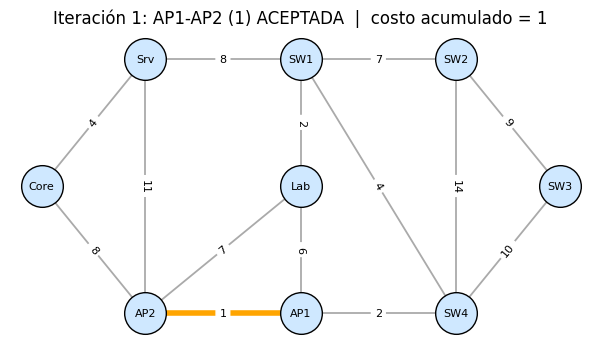

Iteración 2: evaluando SW1 - Lab (costo 2)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 2 | Costo acumulado: 3
Componentes: [['Core'], ['Srv'], ['AP2', 'AP1'], ['SW1', 'Lab'], ['SW2'], ['SW4'], ['SW3']]


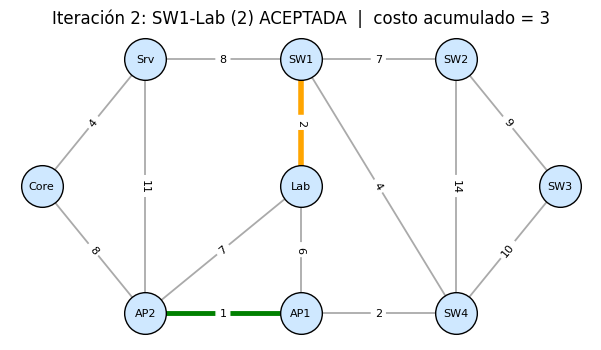

Iteración 3: evaluando SW4 - AP1 (costo 2)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 3 | Costo acumulado: 5
Componentes: [['Core'], ['Srv'], ['AP2', 'SW4', 'AP1'], ['SW1', 'Lab'], ['SW2'], ['SW3']]


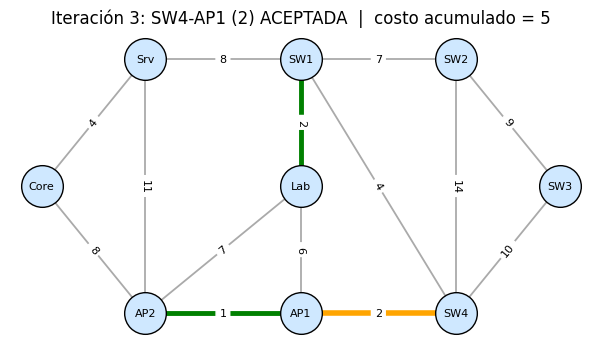

Iteración 4: evaluando Core - Srv (costo 4)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 4 | Costo acumulado: 9
Componentes: [['Core', 'Srv'], ['AP2', 'SW4', 'AP1'], ['SW1', 'Lab'], ['SW2'], ['SW3']]


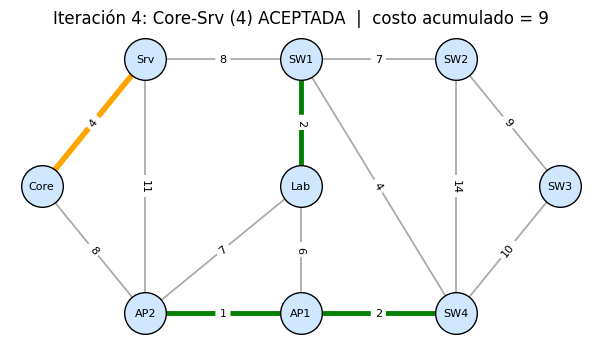

Iteración 5: evaluando SW1 - SW4 (costo 4)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 5 | Costo acumulado: 13
Componentes: [['Core', 'Srv'], ['AP2', 'SW1', 'SW4', 'Lab', 'AP1'], ['SW2'], ['SW3']]


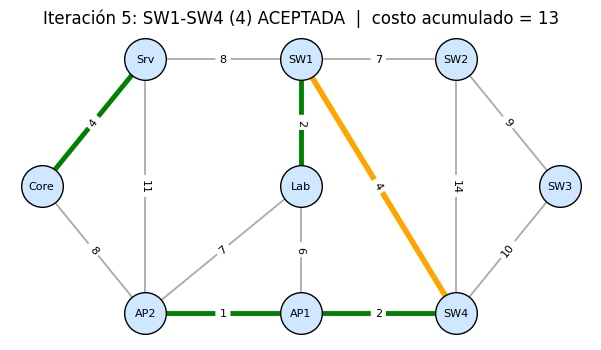

Iteración 6: evaluando AP1 - Lab (costo 6)
Decisión: RECHAZADA (formaría un ciclo)
Aristas aceptadas: 5 | Costo acumulado: 13
Componentes: [['Core', 'Srv'], ['AP2', 'SW1', 'SW4', 'Lab', 'AP1'], ['SW2'], ['SW3']]


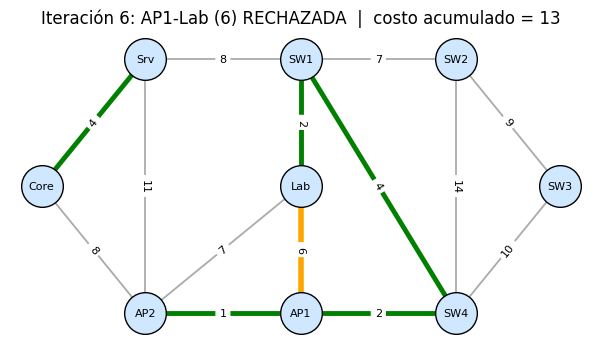

Iteración 7: evaluando SW1 - SW2 (costo 7)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 6 | Costo acumulado: 20
Componentes: [['Core', 'Srv'], ['AP2', 'SW1', 'SW2', 'SW4', 'Lab', 'AP1'], ['SW3']]


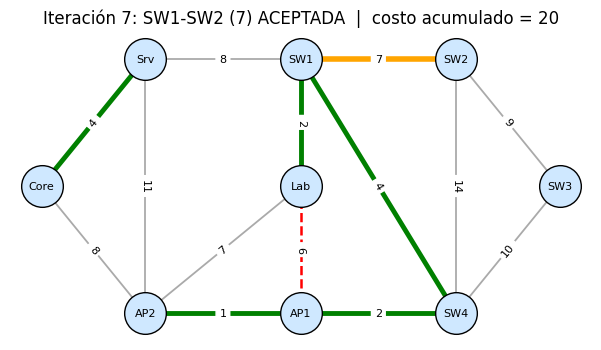

Iteración 8: evaluando AP2 - Lab (costo 7)
Decisión: RECHAZADA (formaría un ciclo)
Aristas aceptadas: 6 | Costo acumulado: 20
Componentes: [['Core', 'Srv'], ['AP2', 'SW1', 'SW2', 'SW4', 'Lab', 'AP1'], ['SW3']]


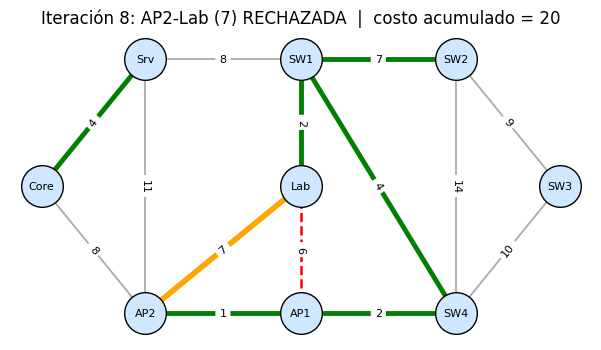

Iteración 9: evaluando Core - AP2 (costo 8)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 7 | Costo acumulado: 28
Componentes: [['Core', 'Srv', 'AP2', 'SW1', 'SW2', 'SW4', 'Lab', 'AP1'], ['SW3']]


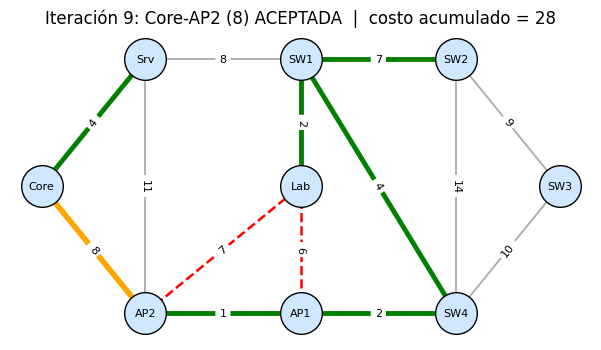

Iteración 10: evaluando Srv - SW1 (costo 8)
Decisión: RECHAZADA (formaría un ciclo)
Aristas aceptadas: 7 | Costo acumulado: 28
Componentes: [['Core', 'Srv', 'AP2', 'SW1', 'SW2', 'SW4', 'Lab', 'AP1'], ['SW3']]


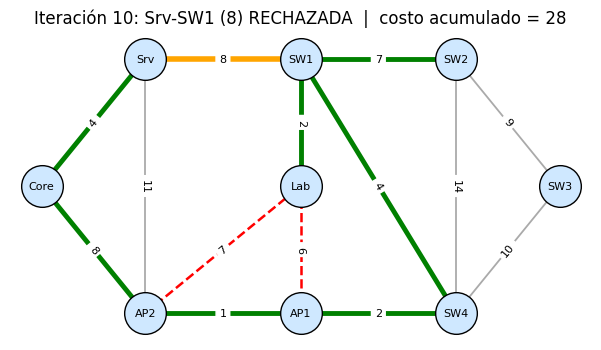

Iteración 11: evaluando SW2 - SW3 (costo 9)
Decisión: ACEPTADA (une dos componentes distintas)
Aristas aceptadas: 8 | Costo acumulado: 37
Componentes: [['Core', 'Srv', 'AP2', 'SW1', 'SW2', 'SW4', 'Lab', 'SW3', 'AP1']]


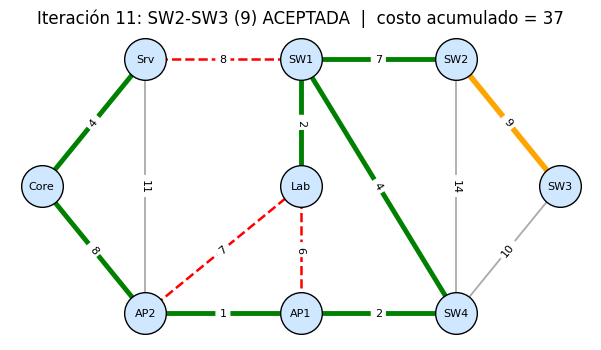


Se alcanzaron |V|-1 = 8 aristas: el algoritmo termina.


In [8]:
uf = UnionFind(G.nodes())
mst, rechazadas = [], []

for i, arista in enumerate(ordenadas, start=1):
    u, v, w = arista
    print("=" * 60)
    print(f"Iteración {i}: evaluando {u} - {v} (costo {w})")
    if uf.unir(u, v):
        mst.append(arista)
        decision = "ACEPTADA (une dos componentes distintas)"
    else:
        rechazadas.append(arista)
        decision = "RECHAZADA (formaría un ciclo)"
    print("Decisión:", decision)
    print("Aristas aceptadas:", len(mst), "| Costo acumulado:", sum(e[2] for e in mst))
    print("Componentes:", uf.componentes())

    dibujar(mst, rechazadas, actual=arista,
            titulo=f"Iteración {i}: {u}-{v} ({w}) {decision.split(' ')[0]}  |  costo acumulado = {sum(e[2] for e in mst)}")

    if len(mst) == G.number_of_nodes() - 1:
        print()
        print("Se alcanzaron |V|-1 = 8 aristas: el algoritmo termina.")
        break

## Paso 7. Visualización de resultados: red original vs. árbol de expansión mínima

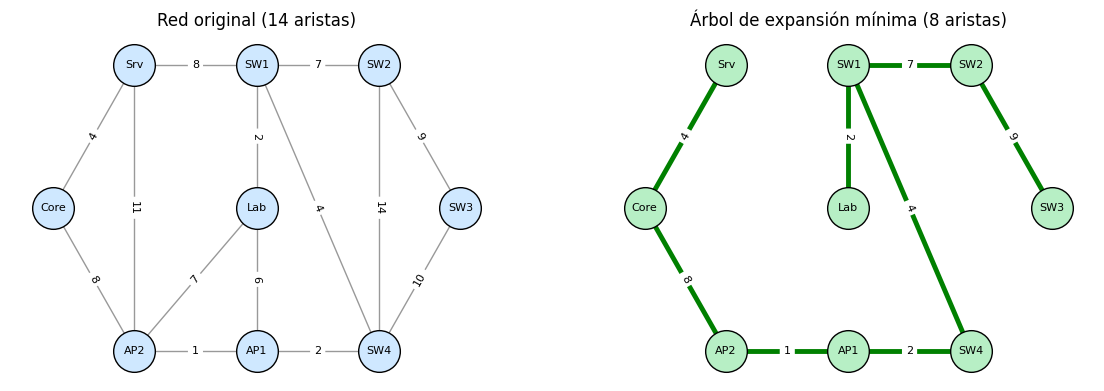

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))

nx.draw(G, pos, ax=axs[0], with_labels=True, node_size=900, node_color="#cfe8ff",
        edgecolors="black", font_size=8, edge_color="#999999")
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"),
                             font_size=8, ax=axs[0])
axs[0].set_title("Red original (14 aristas)")

T = nx.Graph()
T.add_weighted_edges_from(mst)
nx.draw(T, pos, ax=axs[1], with_labels=True, node_size=900, node_color="#b7efc5",
        edgecolors="black", font_size=8, edge_color="green", width=3.5)
nx.draw_networkx_edge_labels(T, pos, nx.get_edge_attributes(T, "weight"),
                             font_size=8, ax=axs[1])
axs[1].set_title("Árbol de expansión mínima (8 aristas)")
plt.show()

## Paso 8. Cálculo del costo mínimo total

In [10]:
res = pd.DataFrame(mst, columns=["Origen", "Destino", "Costo"])
print(res.to_string(index=False))
costo_mst = res["Costo"].sum()
costo_total = df["Costo"].sum()
print()
print("Costo mínimo total del MST :", costo_mst, "(cientos de USD)")
print("Costo de instalar TODOS los tendidos:", costo_total)
print("Ahorro:", costo_total - costo_mst, f"({(costo_total - costo_mst) / costo_total:.1%})")
print("Número de aristas del árbol:", len(mst), "= |V|-1 =", G.number_of_nodes() - 1)
print("¿Es árbol y conecta todo?:", nx.is_tree(T))

Origen Destino  Costo
   AP1     AP2      1
   SW1     Lab      2
   SW4     AP1      2
  Core     Srv      4
   SW1     SW4      4
   SW1     SW2      7
  Core     AP2      8
   SW2     SW3      9

Costo mínimo total del MST : 37 (cientos de USD)
Costo de instalar TODOS los tendidos: 93
Ahorro: 56 (60.2%)
Número de aristas del árbol: 8 = |V|-1 = 8
¿Es árbol y conecta todo?: True


## Paso 9. Verificación con NetworkX

Comparamos el resultado de nuestra implementación con la función incorporada `minimum_spanning_tree` (algoritmos Kruskal y Prim).

In [9]:
for algoritmo in ["kruskal", "prim"]:
    Tn = nx.minimum_spanning_tree(G, algorithm=algoritmo)
    peso = Tn.size(weight="weight")
    print(f"NetworkX ({algoritmo:7s}) -> costo = {peso:.0f}")
print(f"Implementación propia (Kruskal) -> costo = {costo_mst}")
print("Coinciden:", nx.minimum_spanning_tree(G).size(weight="weight") == costo_mst)

NetworkX (kruskal) -> costo = 37
NetworkX (prim   ) -> costo = 37
Implementación propia (Kruskal) -> costo = 37
Coinciden: True


# Interpretación de resultados

- El árbol de expansión mínima utiliza **8 tendidos** (los necesarios para conectar 9 nodos) con un **costo mínimo total de 37** (cientos de USD, es decir, 3,700 USD).
- Instalar los 14 tendidos costaría 93, así que el MST **ahorra 56 unidades (≈60 %)** sin dejar ningún dispositivo aislado.
- Las aristas rechazadas (por ejemplo `Srv-SW1`, que ya estaba conectado a través de `Core` y `AP2`) se descartaron porque **cerrarían un ciclo**: serían cableado redundante.
- La verificación con NetworkX (Kruskal y Prim) da exactamente el mismo costo, lo que valida la implementación.
- El MST es **mínimo** pero no tolerante a fallas: si se corta un cable del árbol, una parte de la red queda desconectada.

## Aplicación al área de Tecnologías de la Información

- **Diseño de redes LAN/WAN y cableado estructurado:** minimizar metros de fibra o cobre para interconectar switches, racks y sedes.
- **Topología de enlaces entre centros de datos** y diseño de redes de distribución de contenido.
- **Protocolo Spanning Tree (STP, IEEE 802.1D):** los switches calculan un árbol de expansión para evitar *loops* de capa 2.
- **Clustering jerárquico** y análisis de datos (el MST agrupa puntos por cercanía) y **redes de sensores IoT**.

## Conclusiones del equipo


El algoritmo de Kruskal permitió obtener, de forma sistemática, la red de menor costo que conecta todos los dispositivos. Visualizar cada iteración ayudó a comprender por qué una arista se acepta o se rechaza (detección de ciclos con Union-Find). El costo mínimo de 37 coincidió con el de NetworkX, y el ahorro frente a instalar todos los tendidos fue de aproximadamente 60 %. Este modelo es directamente aplicable al diseño de redes en TI.


## Conclusiones individuales

| Integrante | Conclusión individual |
|---|---|
 Conclusion (David Alberto): |Tenemos un claro ejemplo de como utilizar de manera optima esta expansion minima y su aplicacion que tiene a problemas de la vida cotidiana, es muy util a la hora de recorrer caminos, cableados, rutas, etc, y poder realizarlo con el menor costo o distancia |
Conclusion (Alexia Guadalupe):|Con esta práctica aprendí cómo funciona el algoritmo de Kruskal y cómo permite conectar todos los puntos de una red utilizando el menor costo posible. También pude comprender mejor el uso de los grafos mediante las representaciones gráficas en Jupyter Notebook. Finalmente, entendí que estos algoritmos son útiles para resolver problemas reales, ahorrar recursos y diseñar redes de manera más eficiente.
